In [1]:
# Owner: FOTSING TANKOU DAN KATEL, M4b

# 05 — CatBoost (out-of-course algorithm) and interpretation of risk factors
**Owner:** FOTSING TANKOU DAN KATEL (M4b) · **Reviewer:** Sharan (M3)

**Goal:** (1) add an algorithm that is not taught in the course, CatBoost, explain its paper and score it exactly like the other models; (2) explain which circumstances are **associated with** a person being killed or seriously injured (KSI).

**How the numbers were produced** (code in `src/models/catboost_model.py` and `src/models/run_catboost.py`; about 7 hours on an 8-core laptop):
```
python -m src.models.run_catboost all     # tune -> oof -> interpret
```
This notebook only **reads** the saved results (and the saved fold-1 model for SHAP by category), so it runs in a few minutes.

**Rules followed (M4_GUIDE section 1):**
- training years 2019–2023 only; the test years 2024–2025 are **not used** in this notebook;
- the shared 5 folds grouped by accident (`get_cv`), PR-AUC as main score, `evaluate()` for the other metrics;
- same input columns as M2's preprocessor (`NUMERIC_FEATURES` + `CATEGORICAL_FEATURES`), so the comparison with the other models is fair;
- one CatBoost model fitted per fold (CatBoost is not a scikit-learn Pipeline, but its only preparation, `to_catboost_frame`, is row-wise and learns nothing from the data);
- threshold for precision / recall / F2 chosen on out-of-fold training predictions with `best_f2_threshold`;
- `RANDOM_STATE` everywhere; `catboost==1.2.10` and `shap==0.54.1` pinned in `requirements.txt`.

## 1. The paper in our own words
L. Prokhorenkova, G. Gusev, A. Vorobev, A. V. Dorogush, A. Gulin. *CatBoost: unbiased boosting with categorical features.* NeurIPS 2018. [arXiv:1706.09516](https://arxiv.org/abs/1706.09516)

**Problem.** Gradient boosting needs numbers, but 32 of our 41 input columns are categories (department, road type, manoeuvre, safety equipment, ...). One-hot encoding creates hundreds of sparse columns (about 100 departments alone). The usual alternative, *target encoding* (replace a category by its mean KSI rate), uses the label of the row itself: this is **target leakage**. A rare category seen once "contains" its own answer, the model over-trusts it, and it does worse on new data. The paper calls the resulting gap between training and test behaviour a *prediction shift*.

**Idea 1: ordered target statistics.** Put the rows in a random order. Row *k* is encoded with the KSI rate of its category computed **only on the rows before it**:
$\hat{x}_k = \dfrac{\sum_{j<k,\ x_j = x_k} y_j + a\,p}{\#\{j<k,\ x_j = x_k\} + a}$ (with a prior $p$ and weight $a$).
Its own label is never used, so there is no leakage, and no data has to be set aside (unlike a hold-out encoding). Several random orders are used to reduce the noise for the first rows.

**Idea 2: ordered boosting.** In classic boosting, the residual of a row is computed by a model that was already trained on that same row, so residuals are too optimistic (another prediction shift). Ordered boosting computes the residual of row *k* with a model trained only on the rows before it.

**Other design choices.** *Oblivious* (symmetric) trees: the same split is used across a whole level, which is fast to evaluate and acts as regularisation. CatBoost also builds **combinations of categories** greedily (for example road user × road type).

**Experiments in the paper.** On about ten public classification datasets, CatBoost obtains a lower log-loss than XGBoost and LightGBM; ablation studies show that removing ordered target statistics or ordered boosting each makes results worse.

**Limits.** Slower to train than LightGBM on CPU; ordered boosting is expensive on large data; predicted probabilities are not guaranteed to be calibrated; like every boosting model, it is harder to read than a logistic regression (hence section 5).

**What our runs actually use (checked).** With `catboost==1.2.10` on CPU, the default `boosting_type` is `"Plain"` (we checked with `get_all_params()`; see the cell below). So our models use **ordered target statistics for the categories** (always on), but **not ordered boosting**. Comparing with `boosting_type="Ordered"` is possible but much slower; we leave it as a limitation.

In [2]:
import json
import sys
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # repo root, when run from notebooks/

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier, Pool
from sklearn.calibration import calibration_curve
from sklearn.metrics import average_precision_score

from src.config import FIGURES_DIR, PROCESSED_DIR, RESULTS_DIR
from src.features.preprocess import CATEGORICAL_FEATURES, NUMERIC_FEATURES

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)

fold1 = CatBoostClassifier().load_model(str(PROCESSED_DIR / "catboost_fold1.cbm"))
print("boosting_type used:", fold1.get_all_params()["boosting_type"])
print(f"{len(NUMERIC_FEATURES)} numeric + {len(CATEGORICAL_FEATURES)} categorical input columns")

boosting_type used: Plain
9 numeric + 32 categorical input columns


## 2. Tuning on a subsample of whole accidents
One fit with 1,000 trees on 80,000 people takes about 1.5 to 2.5 minutes, so the grid of the guide (depth 4/6/8, learning rate 0.03/0.1, 500–1000 iterations, `l2_leaf_reg`) was run with 5 grouped folds on **99,999 people drawn as whole accidents** (44,069 accidents, `accident_subsample` from AutoML v0.1), in three stages:
1. depth × learning rate with the default `l2_leaf_reg = 3`, class weights `"Balanced"`;
2. `l2_leaf_reg` 1 and 10 around the best stage-1 setting;
3. the best setting **without** class weights (imbalance check).

Each model is trained with 1,000 trees; the 500-tree score is read from the first 500 trees of the same model. **No early stopping on the validation fold**: choosing the number of trees on the fold that is then used for scoring would make the score optimistic.

In [3]:
tuning = pd.read_csv(RESULTS_DIR / "catboost_tuning.csv")
best = json.loads((RESULTS_DIR / "catboost_best_params.json").read_text())
print("Best setting:", best)
tuning.head(10)

Best setting: {'depth': 8, 'learning_rate': 0.03, 'l2_leaf_reg': 1.0, 'iterations': 1000, 'auto_class_weights': None}


,depth,learning_rate,l2_leaf_reg,iterations,pr_auc_mean,pr_auc_std,stage,auto_class_weights
0,8,0.03,1.0,1000,0.6326,0.0054,2,Balanced
1,8,0.03,3.0,1000,0.6318,0.0063,1,Balanced
2,8,0.03,10.0,1000,0.6316,0.0056,2,Balanced
3,6,0.10,3.0,1000,0.6310,0.0049,1,Balanced
4,8,0.10,3.0,500,0.6297,0.0047,1,Balanced
5,6,0.10,3.0,500,0.6292,0.0059,1,Balanced
6,6,0.03,3.0,1000,0.6290,0.0063,1,Balanced
7,4,0.10,3.0,1000,0.6285,0.0069,1,Balanced
8,8,0.03,1.0,500,0.6281,0.0068,2,Balanced
9,8,0.03,3.0,500,0.6280,0.0072,1,Balanced


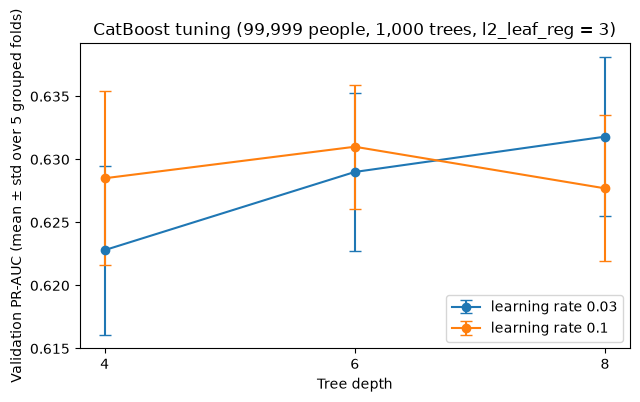

In [4]:
s1 = tuning[(tuning.stage == 1) & (tuning.iterations == 1000)]
fig, ax = plt.subplots(figsize=(6.5, 4))
for lr, g in s1.groupby("learning_rate"):
    g = g.sort_values("depth")
    ax.errorbar(g.depth, g.pr_auc_mean, yerr=g.pr_auc_std, marker="o", capsize=4, label=f"learning rate {lr}")
ax.set(xlabel="Tree depth", ylabel="Validation PR-AUC (mean ± std over 5 grouped folds)",
       title="CatBoost tuning (99,999 people, 1,000 trees, l2_leaf_reg = 3)", xticks=[4, 6, 8])
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "m4_catboost_tuning.png", dpi=150)
plt.show()

**Reading.** Deeper trees help a little (more interactions between categories), and with a small learning rate 1,000 trees beat 500. But all settings from depth 6 are within about 0.004 PR-AUC, smaller than one fold-to-fold standard deviation (≈ 0.005–0.007): CatBoost is not very sensitive to its settings here.

**Class weights.** Without weights the score is 0.6331 vs 0.6326 with `"Balanced"`: a difference of 0.0005, far inside the noise. The run kept the unweighted model (highest mean). This choice has one practical advantage: without re-weighting, the predicted probabilities are not pushed up artificially, so they can be read as KSI risks (checked in section 4). The F2 threshold then simply moves lower.

## 3. Out-of-fold results on all training years (619,552 people)
The best setting was refitted once per shared grouped fold (the same 5 folds as the logistic baseline), so each person is predicted by a model that never saw their accident.

In [5]:
base = pd.read_csv(RESULTS_DIR / "baseline_train.csv")
cat = pd.read_csv(RESULTS_DIR / "catboost_train.csv")
comparison = pd.concat([base, cat], ignore_index=True).set_index("model")
comparison.drop(columns="scored_on").round(4)

,pr_auc,roc_auc,precision,recall,f2,threshold,predicted_ksi_share
model,,,,,,,
Majority class,0.1803,0.5000,0.0000,0.0000,0.0000,0.5000,0.0000
Expert rule,0.2513,0.6537,0.2819,0.6992,0.5395,0.5000,0.4471
Logistic regression,0.5887,0.8722,0.4363,0.8194,0.6970,0.5000,0.3386
Logistic regression (F2 threshold),0.5887,0.8722,0.3963,0.8744,0.7045,0.4151,0.3978
CatBoost,0.6471,0.8887,0.6792,0.4707,0.5015,0.5000,0.1249
CatBoost (F2 threshold),0.6471,0.8887,0.4274,0.8690,0.7202,0.1469,0.3666


In [6]:
automl = json.loads((RESULTS_DIR / "automl_v01_best_params.json").read_text())
automl_table = pd.DataFrame({m: {"cv_pr_auc_mean": v["cv_pr_auc_mean"], "cv_pr_auc_std": v["cv_pr_auc_std"],
                                 "subsample_people": v["subsample_people"]} for m, v in automl.items()}).T
cb_sub = tuning.iloc[0]
automl_table.loc["CatBoost (this notebook)"] = [cb_sub.pr_auc_mean, cb_sub.pr_auc_std, 99_999]
automl_table.sort_values("cv_pr_auc_mean", ascending=False).round(4)

,cv_pr_auc_mean,cv_pr_auc_std,subsample_people
CatBoost (this notebook),0.6326,0.0054,99999.0
Logistic regression,0.5897,0.0067,99999.0
SVM,0.5805,0.0123,10000.0
Random forest,0.5797,0.0111,29999.0
k-nearest neighbours,0.5396,0.0072,19998.0
Decision tree,0.5304,0.0104,29999.0


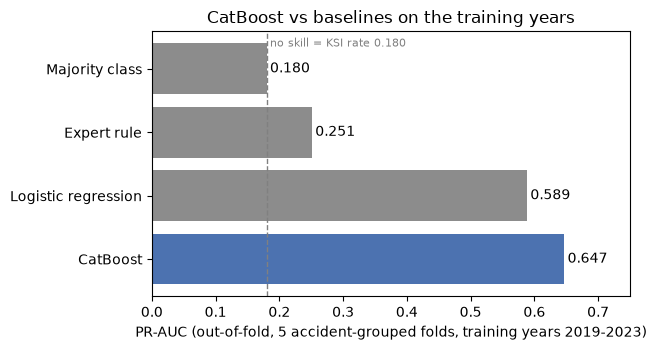

Per-fold PR-AUC: {1: 0.6453, 2: 0.6483, 3: 0.6458, 4: 0.6482, 5: 0.6481}


In [7]:
oof = pd.read_parquet(PROCESSED_DIR / "catboost_oof.parquet")
ksi_rate = oof.KSI.mean()
rows = comparison.loc[["Majority class", "Expert rule", "Logistic regression", "CatBoost"], "pr_auc"]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.barh(rows.index[::-1], rows.values[::-1], color=["#4C72B0", "#8C8C8C", "#8C8C8C", "#8C8C8C"])
for i, v in enumerate(rows.values[::-1]):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center")
ax.axvline(ksi_rate, color="grey", ls="--", lw=1)
ax.text(ksi_rate + 0.005, 3.35, f"no skill = KSI rate {ksi_rate:.3f}", fontsize=8, color="grey")
ax.set(xlabel="PR-AUC (out-of-fold, 5 accident-grouped folds, training years 2019-2023)", xlim=(0, 0.75),
       title="CatBoost vs baselines on the training years")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "m4_catboost_vs_baselines.png", dpi=150)
plt.show()
per_fold = {k: round(average_precision_score(g.KSI, g.proba), 4) for k, g in oof.groupby("fold")}
print("Per-fold PR-AUC:", per_fold)

**Reading.**
- CatBoost reaches an out-of-fold **PR-AUC of 0.647** vs **0.589** for the logistic baseline (+0.058) and ROC-AUC 0.889 vs 0.872, on exactly the same folds. The 5 folds are very stable (0.645–0.648), so the gain is far larger than the fold-to-fold variation. It also beats every AutoML v0.1 model on the subsample comparison (0.633 vs 0.590 for the best logistic regression and 0.580 for the random forest).
- At the best-F2 threshold (0.147, chosen on these out-of-fold predictions), CatBoost finds **86.9 % of KSI people** with a precision of 42.7 % (F2 = 0.720), vs 87.4 % / 39.6 % (F2 = 0.705) for the logistic regression: about the same recall with fewer false alarms.
- Likely reasons: CatBoost uses the categories without one-hot encoding and learns **interactions** (e.g. motorcyclist × 80 km/h road × fixed obstacle) that a linear model cannot represent without hand-made features.
- These are training-year (validation) scores. The final, uncertainty-aware comparison (95 % bootstrap intervals, paired difference vs the baseline) is done **once** on the test years 2024–2025 in the final evaluation (`src/models/final_evaluation.py`, M4_GUIDE section 6).

## 4. Are the predicted probabilities trustworthy? (calibration)
If the model says "30 % risk" for a group of people, about 30 % of them should be KSI.

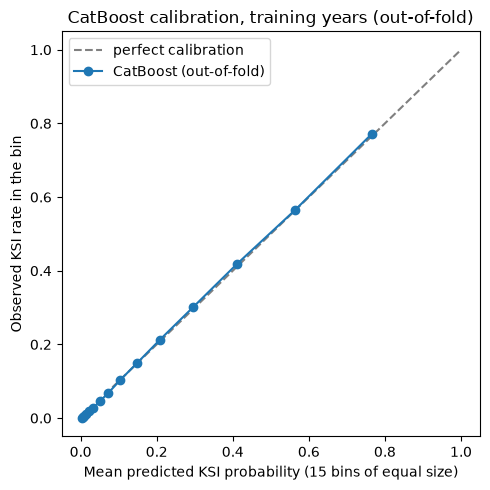

Mean predicted probability 0.180 vs observed KSI rate 0.180; largest gap between bins: 0.007


In [8]:
frac_pos, mean_pred = calibration_curve(oof.KSI, oof.proba, n_bins=15, strategy="quantile")
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], "--", color="grey", label="perfect calibration")
ax.plot(mean_pred, frac_pos, "o-", label="CatBoost (out-of-fold)")
ax.set(xlabel="Mean predicted KSI probability (15 bins of equal size)", ylabel="Observed KSI rate in the bin",
       title="CatBoost calibration, training years (out-of-fold)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "m4_catboost_calibration.png", dpi=150)
plt.show()
print(f"Mean predicted probability {oof.proba.mean():.3f} vs observed KSI rate {ksi_rate:.3f}; "
      f"largest gap between bins: {np.max(np.abs(frac_pos - mean_pred)):.3f}")

**Reading.** The points lie close to the diagonal: since the final model is trained without class weights, its probabilities can be read as KSI risks (useful for the table of situations in section 6). With `"Balanced"` weights they would have been pushed up.

## 5. Which circumstances are associated with KSI?
Both methods use the **fold-1 model** (trained on folds 2–5) on **29,997 people from 13,303 fold-1 validation accidents** that this model never saw. Measuring importance on training data would show what the model memorised, not what generalises.

- **Permutation importance:** PR-AUC lost when one column is shuffled (5 repeats). Global, directly in our metric. Limit: when columns carry the same information (`catu`, `place`, `road_user`, `locp` all partly say "pedestrian"), shuffling one of them underestimates it because the others compensate.
- **SHAP values:** exact tree SHAP computed by CatBoost; the contribution of each column to each person's prediction, in log-odds. They add up to the prediction, so they also show the **direction** of the effect per category.

In [9]:
perm = pd.read_csv(RESULTS_DIR / "catboost_permutation_importance.csv")
shap_imp = pd.read_csv(RESULTS_DIR / "catboost_shap_importance.csv")
ranks = (perm.reset_index().rename(columns={"index": "perm_rank"})[["feature", "perm_rank", "pr_auc_drop_mean"]]
         .merge(shap_imp.reset_index().rename(columns={"index": "shap_rank"})[["feature", "shap_rank", "mean_abs_shap"]]))
ranks[["perm_rank", "shap_rank"]] += 1
ranks.head(12)

,feature,perm_rank,pr_auc_drop_mean,shap_rank,mean_abs_shap
0,dep,1,0.09615,3,0.37187
1,road_user,2,0.08271,2,0.37245
2,secu1,3,0.06826,1,0.42193
3,obsm,4,0.03701,7,0.17337
4,age,5,0.03692,6,0.19102
5,obs,6,0.02562,10,0.16120
6,locp,7,0.02109,4,0.22475
7,col,8,0.01936,5,0.20087
8,secu2,9,0.01273,12,0.13076
9,choc,10,0.01062,11,0.13471


![Permutation importance](../report/figures/m4_catboost_permutation_importance.png)
![SHAP summary](../report/figures/m4_catboost_shap_summary.png)

The two methods agree on the top group: **department (`dep`), road user, safety equipment (`secu1`), age, obstacles hit (`obsm`, `obs`), pedestrian location (`locp`) and collision type (`col`)**. On the beeswarm, older age and higher speed limits push the predicted risk up (red points to the right).

### SHAP by category: in which direction?
Mean SHAP value of each category on the same unseen people (positive = associated with higher KSI risk than average). Code meanings are from the official ONISR dictionary.

In [10]:
from src.features.build_features import add_features
from src.features.split import get_cv, get_splits
from src.models.automl import accident_subsample
from src.models.catboost_model import FEATURES, to_catboost_frame

persons = pd.read_parquet(PROCESSED_DIR / "persons.parquet")
X, y, groups, _, _ = get_splits(add_features(persons))         # test part ignored on purpose
train_idx, valid_idx = next(get_cv().split(X, y, groups))      # fold 1, same as run_catboost
Xv, yv, gv = accident_subsample(X.iloc[valid_idx], y.iloc[valid_idx], groups.iloc[valid_idx], 30_000)
Xc = to_catboost_frame(Xv)
sv = fold1.get_feature_importance(Pool(Xc, cat_features=CATEGORICAL_FEATURES), type="ShapValues")[:, :-1]
shap_df = pd.DataFrame(sv, columns=FEATURES, index=Xc.index)
print(f"{len(Xv):,} unseen people from {gv.nunique():,} accidents")

29,997 unseen people from 13,303 accidents


In [11]:
LABELS = {
    "secu1": {"0": "no equipment", "1": "belt", "2": "helmet", "3": "child seat", "4": "reflective vest",
              "5": "airbag (2/3 wheels)", "6": "gloves", "7": "gloves + airbag", "8": "undeterminable",
              "9": "other", "missing": "missing"},
    "obsm": {"0": "none", "1": "pedestrian", "2": "vehicle", "4": "rail vehicle", "5": "domestic animal",
             "6": "wild animal", "9": "other", "missing": "missing"},
    "col": {"1": "2 vehicles, frontal", "2": "2 vehicles, rear", "3": "2 vehicles, side", "4": "3+ vehicles, chain",
            "5": "3+ vehicles, multiple", "6": "other collision", "7": "no collision", "missing": "missing"},
}

def shap_by_category(col, min_people=100):
    t = pd.DataFrame({"category": Xc[col], "shap": shap_df[col], "KSI": yv})
    g = t.groupby("category").agg(people=("shap", "size"), mean_shap=("shap", "mean"), observed_ksi=("KSI", "mean"))
    g = g[g.people >= min_people].sort_values("mean_shap", ascending=False)
    if col in LABELS:
        g.insert(0, "meaning", [LABELS[col].get(c, "?") for c in g.index])
    return g.round(3)

for col in ["road_user", "secu1", "obsm", "col"]:
    print(f"\n=== {col} ===")
    print(shap_by_category(col).to_string())


=== road_user ===
                             people  mean_shap  observed_ksi
category                                                    
Motorcycle >50cc               3319      0.721         0.367
E-bike                          121      0.670         0.289
Bicycle                        1225      0.597         0.304
Pedestrian                     2342      0.574         0.323
Moped <50cc                    1735      0.528         0.302
E-scooter / personal device     415      0.217         0.171
Other / unknown                 516      0.049         0.153
Car                           17389     -0.234         0.128
Van                            1883     -0.392         0.064
Heavy goods vehicle             676     -0.437         0.058
Bus / coach                     329     -0.656         0.021

=== secu1 ===
                 meaning  people  mean_shap  observed_ksi
category                                                 
2                 helmet    5438      0.679         0.337

In [12]:
dep = shap_by_category("dep", min_people=150)
print("Departments with the highest and lowest mean SHAP (>= 150 unseen people):")
pd.concat([dep.head(8), dep.tail(8)])

Departments with the highest and lowest mean SHAP (>= 150 unseen people):


,people,mean_shap,observed_ksi
category,,,
84,153,0.631,0.373
62,314,0.627,0.322
85,186,0.556,0.371
59,517,0.470,0.298
34,348,0.467,0.290
57,190,0.460,0.321
30,231,0.444,0.294
83,460,0.421,0.293
10,193,-0.080,0.176


### Comparison with the logistic odds ratios and the EDA

In [13]:
odds = pd.read_csv(RESULTS_DIR / "logreg_odds_ratios.csv")
pd.concat([odds.head(10), odds.tail(8)])[["feature", "odds_ratio"]].round(3)

,feature,odds_ratio
0,obsm_4,4.779
1,road_user_E-bike,3.176
2,road_user___MISSING__,2.669
3,road_user_Motorcycle >50cc,2.581
4,infra_7,2.530
5,road_user_Bicycle,2.523
6,road_user_E-scooter / personal device,2.489
7,road_user_Moped <50cc,2.215
8,dep_84,2.147
9,manv_6,2.112


**Reading (wording: "associated with", never "causes").**
- **Road user** is near the top for both models: unprotected users (pedestrians, two-wheelers) have positive SHAP values and odds ratios > 1, while bus, heavy-goods-vehicle and van occupants are strongly protective. This matches the EDA (motorcyclists 36 % KSI).
- **Safety equipment (`secu1`)**: "no equipment" (39 % KSI on these people) and "helmet" (34 %) have the largest positive SHAP values, "belt" a negative one (10 %). This mostly says **who** the person is: a helmet means a two-wheeler, a belt means a car occupant. Equipment and road user share their importance, so `secu1` must not be read as "helmets are dangerous".
- **Obstacles and collision type**: hitting a fixed obstacle, especially a **tree** (`obs` = 2; EDA 56 % KSI, odds ratio 2.0), raises the risk. "No moving obstacle hit" (`obsm` = 0, 35 % KSI) and "no collision" (`col` = 7, 38 %) both point to **single-vehicle crashes** (leaving the road), which are more severe; frontal collisions between two vehicles (`col` = 1) too. Rear-end and chain collisions are associated with low risk. A vehicle occupant who hit a pedestrian (`obsm` = 1) has a low risk (the pedestrian is the one at risk). A rail vehicle (`obsm` = 4) has the largest logistic odds ratio (4.8) but is too rare to appear in the SHAP table (< 100 people).
- **Age and speed limit**: older people and higher speed limits (80 km/h roads: 39 % KSI in the EDA) are associated with higher risk; the beeswarm shows a monotonic increase that the logistic model can only approximate with one slope.
- **Department** is the most important column for CatBoost and also has extreme odds ratios (Paris `75` and the inner suburbs `92`, `93`, `94` are protective; Vaucluse `84`, Pas-de-Calais `62`, Vendée `85` and Nord `59` have the highest values). Part of this is real (dense urban traffic is slower), but **part may reflect how hospital stays are recorded** in each department, and departments also stand for rural vs urban roads. We report it as an association to investigate, not as a lever for action.
- **Difference between the methods.** The logistic odds ratios are per one-hot column and assume additive effects; CatBoost's SHAP values include interactions. Where both agree (road user, equipment, obstacles, age, speed), the finding is robust.

## 6. High-severity situations for road-safety authorities
Road user × speed limit × fixed obstacle, ranked by the **out-of-fold** predicted KSI rate (each person predicted by a model that never saw their accident). Only situations with at least 300 people are kept; the observed rate has a 95 % Wilson interval. `flagged_share` = share of people above the F2 threshold.

In [14]:
situations = pd.read_csv(RESULTS_DIR / "catboost_high_risk_situations.csv")
print(f"{len(situations)} situations with >= 300 people")
situations.head(15).round(3)

94 situations with >= 300 people


,road_user,speed_limit,fixed_obstacle,people,observed_ksi_rate,observed_ci_low,observed_ci_high,predicted_ksi_rate,flagged_share
0,Motorcycle >50cc,71-80,other fixed obstacle,2375,0.777,0.760,0.793,0.782,1.000
1,Pedestrian,81-110,none,565,0.814,0.780,0.844,0.781,1.000
2,Pedestrian,71-80,none,892,0.759,0.730,0.786,0.771,1.000
3,Moped <50cc,71-80,other fixed obstacle,462,0.656,0.611,0.698,0.702,1.000
4,Motorcycle >50cc,71-80,none,7933,0.683,0.672,0.693,0.684,0.998
5,Bicycle,71-80,none,2519,0.672,0.654,0.690,0.677,0.998
6,Car,71-80,tree,4502,0.651,0.637,0.665,0.650,0.998
7,Bicycle,81-110,none,341,0.604,0.551,0.655,0.645,0.997
8,Moped <50cc,71-80,none,2522,0.647,0.628,0.665,0.628,0.995
9,Pedestrian,51-70,none,757,0.630,0.595,0.664,0.628,0.992


**Reading.** The riskiest situations are all on **roads limited to 70–110 km/h**: motorcyclists hitting a fixed obstacle (78 % KSI, 2,375 people), pedestrians hit on 80–110 km/h roads (76–81 %), cyclists on 80 km/h roads (67 %) and car occupants hitting a **tree** on an 80 km/h road (65 %, 4,502 people). The predicted rates match the observed ones closely (within the Wilson intervals for most rows), which is consistent with the calibration curve. For action, the size of the group matters as much as the rate: "motorcyclist on an 80 km/h road with no obstacle" (68 %, **7,933 people**) and "car on an 80 km/h road with a fixed obstacle other than a tree" (48 %, **11,807 people**) concern many more people.

## 7. Limitations and next step
- **Associations, not causes.** Observational data; no information on speed actually driven, alcohol or drugs (not in the open data), so the model cannot see behaviour.
- **Department effects** may partly reflect recording practices (see section 5).
- **Correlated columns** (road user, user category, seat, equipment, pedestrian location) share importance; permutation importance underestimates each of them.
- **Ordered boosting not used** (CatBoost default `Plain` at this data size); only ordered target statistics.
- **Interpretation from one fold model** on 30,000 unseen people (computing SHAP for 5 models on 619,552 people was not needed to rank the factors; the ranks are stable across methods).
- **Training-year scores only.** The final test (2024–2025), with 95 % bootstrap intervals by whole accidents and the paired difference vs the logistic baseline, is run once with all final models (logistic baseline, best AutoML model, best M4a ensemble, CatBoost) in `src/models/final_evaluation.py`, threshold 0.147 carried over unchanged.